## 1-1. Revenue EDA
- Q. 현재 매출 성장은 어떤 구조에 의해 만들어지고 있는가?
- Objective : 매출, 고객 수, 구매 빈도 및 고객별 매출 구조를 분석해 현재 매출 성장의 특징을 파악

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.ticker as mtick
import seaborn as sns

from scipy import stats
import math

import mysql.connector
import pymysql

import warnings
warnings.filterwarnings("ignore")

In [4]:
records_df = pd.read_sql("""
SELECT *
FROM records
""", conn)

In [5]:
records_df

,order_id,order_date,ship_mode,customer_id,segment,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,CA-2017-107503,2020-01-01,Standard Class,GA-14725,Consumer,Lorain,Ohio,44052,East,FUR-FU-10003878,Furniture,Furnishings,"Linden 10 Round Wall Clock, Black",48.896,4,0.2,8.5568
1,CA-2017-144463,2020-01-01,Standard Class,SC-20725,Consumer,Los Angeles,California,90036,West,FUR-FU-10001215,Furniture,Furnishings,Howard Miller 11-1/2 Diameter Brentwood Wall C...,474.430,11,0.0,199.2606
2,CA-2017-154466,2020-01-01,First Class,DP-13390,Home Office,Franklin,Wisconsin,53132,Central,OFF-BI-10002012,Office Supplies,Binders,Wilson Jones Easy Flow II Sheet Lifters,3.600,2,0.0,1.7280
3,CA-2017-151750,2020-01-01,Standard Class,JM-15250,Consumer,Huntsville,Texas,77340,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,454.560,5,0.2,-107.9580
4,CA-2017-151750,2020-01-01,Standard Class,JM-15250,Consumer,Huntsville,Texas,77340,Central,FUR-FU-10002116,Furniture,Furnishings,"Tenex Carpeted, Granite-Look or Clear Contempo...",141.420,5,0.6,-187.3815
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3270,CA-2017-143259,2020-12-30,Standard Class,PO-18865,Consumer,New York City,New York,10009,East,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279
3271,CA-2017-143259,2020-12-30,Standard Class,PO-18865,Consumer,New York City,New York,10009,East,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910
3272,CA-2017-115427,2020-12-30,Standard Class,EB-13975,Corporate,Fairfield,California,94533,West,OFF-BI-10002103,Office Supplies,Binders,"Cardinal Slant-D Ring Binder, Heavy Gauge Vinyl",13.904,2,0.2,4.5188
3273,CA-2017-115427,2020-12-30,Standard Class,EB-13975,Corporate,Fairfield,California,94533,West,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750


In [6]:
monthly_df = pd.read_sql("""
SELECT DATE_FORMAT(order_date, "%Y-%m") AS month
     , COUNT(DISTINCT order_id) AS order_cnt
     , COUNT(DISTINCT customer_id) AS PU
     , ROUND(SUM(sales), 2) AS revenue
     , ROUND(SUM(sales) / COUNT(DISTINCT order_id), 2) AS AOV
     , ROUND(SUM(sales) / COUNT(DISTINCT customer_id), 2) AS ARPPU
FROM records
GROUP BY month
""", conn)

In [7]:
monthly_df

,month,order_cnt,PU,revenue,AOV,ARPPU
0,2020-01,69,67,43971.37,637.27,656.29
1,2020-02,50,50,20178.38,403.57,403.57
2,2020-03,118,115,58872.35,498.92,511.93
3,2020-04,116,109,36521.54,314.84,335.06
4,2020-05,117,112,44056.13,376.55,393.36
5,2020-06,126,113,52310.22,415.16,462.92
6,2020-07,111,102,45264.42,407.79,443.77
7,2020-08,109,102,62956.07,577.58,617.22
8,2020-09,226,196,87771.90,388.37,447.82
9,2020-10,147,136,77776.92,529.09,571.89


In [8]:
monthly_df["revenue"].sum()

np.float64(729034.1600000001)

In [9]:
x = np.arange(len(monthly_df))

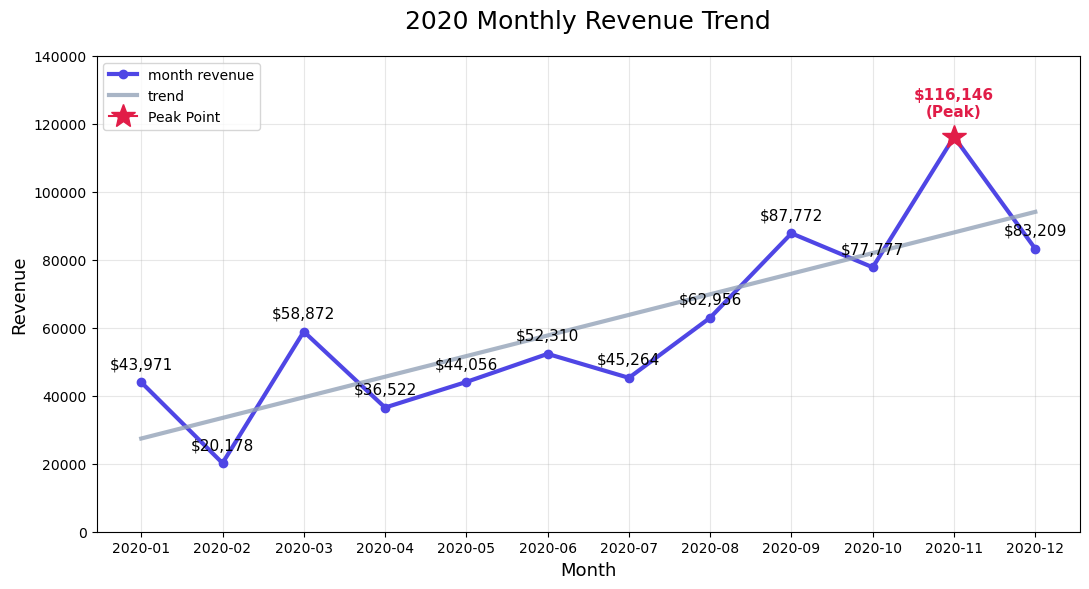

In [10]:
plt.figure(figsize = (11, 6))

# 1. 메인 매출
plt.plot(monthly_df["month"], monthly_df["revenue"], marker = "o", color = "#4F46E5", linewidth = 3, label = "month revenue")

# 2. 추세선
coef = np.polyfit(x, monthly_df["revenue"], 1)
trend = np.poly1d(coef)(x)

plt.plot(monthly_df["month"], trend, linestyle = "-", color = "#94A3B8", linewidth = 3, alpha = 0.8, label = "trend")

# 3. 피크포인트 강조
revenue_list = list(monthly_df["revenue"])
max_val = max(revenue_list)
max_idx = revenue_list.index(max_val)

peak_month = monthly_df["month"][max_idx] if isinstance(monthly_df["month"], list) else monthly_df["month"].iloc[max_idx]
plt.plot(peak_month, max_val, marker = "*", markersize = 18, color = "#E11D48", label = "Peak Point") # 색상 변경

# 4. 데이터 라벨링
for i, value in enumerate(monthly_df["revenue"]):
    if value == max_val:
        font_weight = "bold"
        color = "#E11D48" # 피크 텍스트 강조 색상
        text = f"${value:,.0f}\n(Peak)"
        y_offset = 15 # 텍스트가 마커에 가리지 않게 위로 올림
    else:
        font_weight = "normal"
        color = "black"
        text = f"${value:,.0f}"
        y_offset = 10

    plt.annotate(text
                , (i, value)
                , textcoords = "offset points"
                , xytext = (0, y_offset)
                , ha = "center"
                , fontsize = 11
                , fontweight = font_weight
                , color = color
                )

plt.title("2020 Monthly Revenue Trend", fontsize = 18, pad = 20)
plt.xlabel("Month", fontsize = 13)
plt.ylabel("Revenue", fontsize = 13)
plt.ylim(0, 140000)
plt.grid(alpha = 0.3)
plt.legend()
plt.tight_layout()
plt.show()

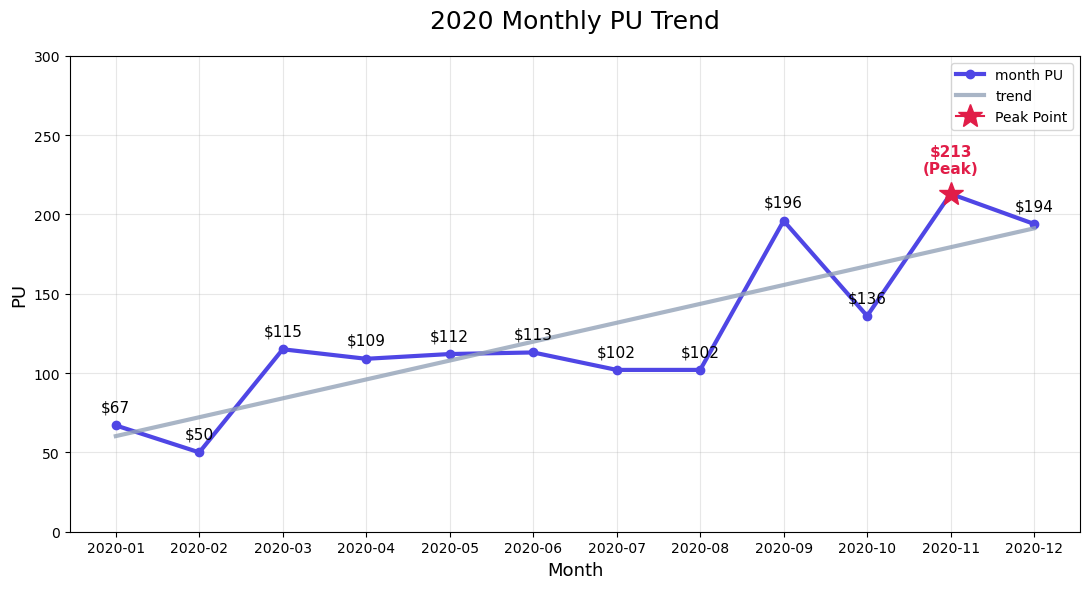

In [11]:
plt.figure(figsize = (11, 6))

# 1. PU
plt.plot(monthly_df["month"], monthly_df["PU"], marker = "o", color = "#4F46E5", linewidth = 3, label = "month PU")

# 2. 추세선
coef = np.polyfit(x, monthly_df["PU"], 1)
trend = np.poly1d(coef)(x)

plt.plot(monthly_df["month"], trend, linestyle = "-", color = "#94A3B8", linewidth = 3, alpha = 0.8, label = "trend")

# 3. 피크포인트 강조
pu_list = list(monthly_df["PU"])
max_val = max(pu_list)
max_idx = pu_list.index(max_val)

peak_month = monthly_df["month"][max_idx] if isinstance(monthly_df["month"], list) else monthly_df["month"].iloc[max_idx]
plt.plot(peak_month, max_val, marker = "*", markersize = 18, color = "#E11D48", label = "Peak Point")

# 4. 데이터 라벨링
for i, value in enumerate(monthly_df["PU"]):
    if value == max_val:
        font_weight = "bold"
        color = "#E11D48"
        text = f"${value:,.0f}\n(Peak)"
        y_offset = 15
    else:
        font_weight = "normal"
        color = "black"
        text = f"${value:,.0f}"
        y_offset = 10

    plt.annotate(text
                , (i, value)
                , textcoords = "offset points"
                , xytext = (0, y_offset)
                , ha = "center"
                , fontsize = 11
                , fontweight = font_weight
                , color = color
                )

plt.title("2020 Monthly PU Trend", fontsize = 18, pad = 20)
plt.xlabel("Month", fontsize = 13)
plt.ylabel("PU", fontsize = 13)
plt.ylim(0, 300)
plt.grid(alpha = 0.3)
plt.legend()
plt.tight_layout()
plt.show()

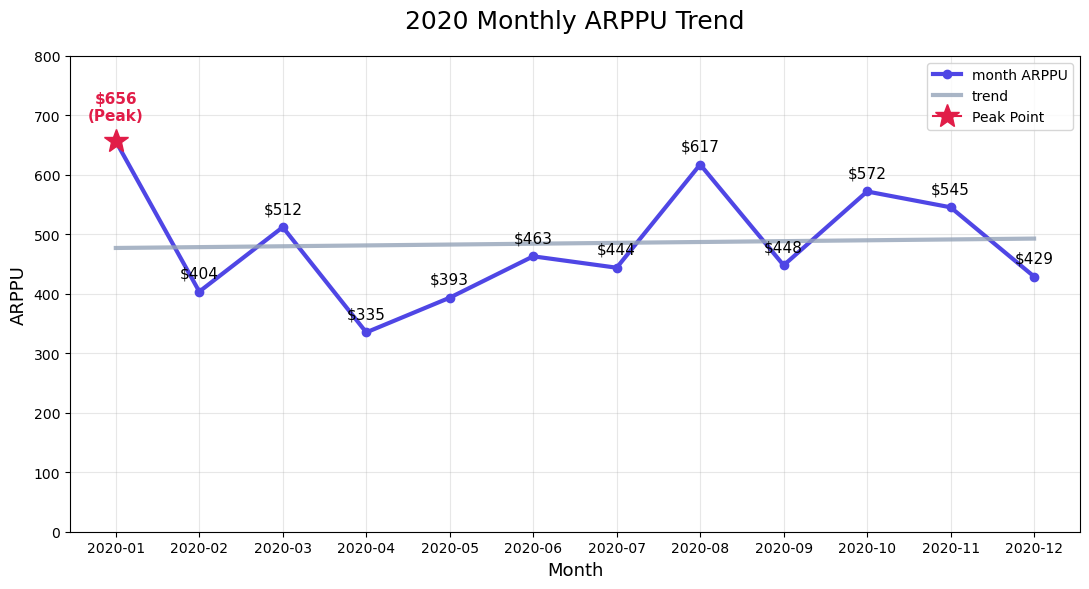

In [12]:
plt.figure(figsize = (11, 6))

# 1. ARPPU
plt.plot(monthly_df["month"], monthly_df["ARPPU"], marker = "o", color = "#4F46E5", linewidth = 3, label = "month ARPPU")

# 2. 추세선
coef = np.polyfit(x, monthly_df["ARPPU"], 1)
trend = np.poly1d(coef)(x)

plt.plot(monthly_df["month"], trend, linestyle = "-", color = "#94A3B8", linewidth = 3, alpha = 0.8, label = "trend")

# 3. 피크포인트 강조
arppu_list = list(monthly_df["ARPPU"])
max_val = max(arppu_list)
max_idx = arppu_list.index(max_val)

peak_month = monthly_df["month"][max_idx] if isinstance(monthly_df["month"], list) else monthly_df["month"].iloc[max_idx]
plt.plot(peak_month, max_val, marker = "*", markersize = 18, color = "#E11D48", label = "Peak Point")

# 4. 데이터 라벨링
for i, value in enumerate(monthly_df["ARPPU"]):
    if value == max_val:
        font_weight = "bold"
        color = "#E11D48"
        text = f"${value:,.0f}\n(Peak)"
        y_offset = 15
    else:
        font_weight = "normal"
        color = "black"
        text = f"${value:,.0f}"
        y_offset = 10

    plt.annotate(text
                , (i, value)
                , textcoords = "offset points"
                , xytext = (0, y_offset)
                , ha = "center"
                , fontsize = 11
                , fontweight = font_weight
                , color = color
                )

plt.title("2020 Monthly ARPPU Trend", fontsize = 18, pad = 20)
plt.xlabel("Month", fontsize = 13)
plt.ylabel("ARPPU", fontsize = 13)
plt.ylim(0, 800)
plt.grid(alpha = 0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 1-2. Customer Behavior
- Q. 고객은 언제 이탈하기 시작하며, 재구매로 이어지는 과정에서 어떤 문제가 발생하는가?
- Objective : 코호트 분석과 구매 주기 분석을 통해 신규 고객의 초기 유지율과 재구매 행동을 파악한다.

In [13]:
customer_type_df = pd.read_sql("""
SELECT segment
	 , COUNT(DISTINCT customer_id) AS customer_cnt
     , COUNT(DISTINCT order_id) AS order_cnt
     , ROUND(SUM(sales), 2) AS revenue
     , ROUND(COUNT(DISTINCT order_id) / COUNT(DISTINCT customer_id), 2) AS orders_per_customer
     , ROUND(SUM(sales) / COUNT(DISTINCT customer_id), 2) AS sales_per_customer
     , ROUND(SUM(sales) / COUNT(DISTINCT order_id), 2) AS aov
     , ROUND(SUM(sales) * 100 / (SELECT SUM(sales) FROM records), 2) revenue_rate
     , ROUND(COUNT(DISTINCT order_id) * 100 / (SELECT COUNT(DISTINCT order_id) FROM records), 3) order_rate
     , ROUND(COUNT(DISTINCT customer_id) * 100 / (SELECT COUNT(DISTINCT customer_id) FROM records), 2) customer_rate
     , ROUND(SUM(profit), 2) AS profit
     , ROUND(SUM(profit) * 100 / SUM(sales), 2) AS profit_margin
     
FROM records
GROUP BY segment
ORDER BY revenue DESC
""", conn)

In [14]:
customer_type_df

,segment,customer_cnt,order_cnt,revenue,orders_per_customer,sales_per_customer,aov,revenue_rate,order_rate,customer_rate,profit,profit_margin
0,Consumer,361,868,330834.34,2.40,916.44,381.15,45.38,52.038,52.09,45442.76,13.74
1,Corporate,204,487,239508.28,2.39,1174.06,491.80,32.85,29.197,29.44,26856.31,11.21
2,Home Office,128,313,158691.53,2.45,1239.78,507.00,21.77,18.765,18.47,20839.06,13.13


In [15]:
plt.rcParams["font.family"] = "san-serif"

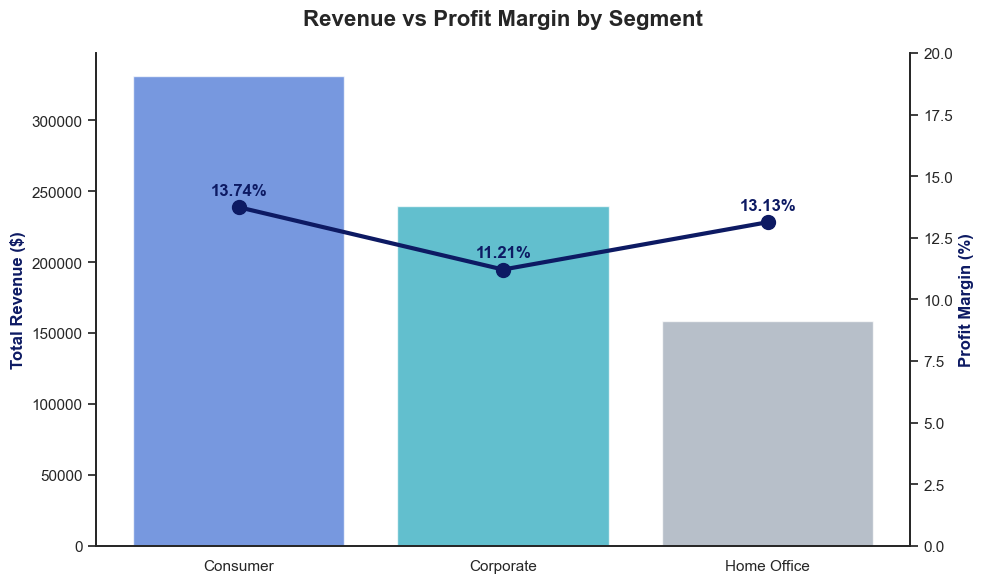

In [16]:
sns.set_theme(style = "white")

fig, ax1 = plt.subplots(figsize = (10, 6))

# 매출 bar chart
palette = ["#2563EB", "#06B6D4", "#94A3B8"]

sns.barplot(x = "segment", y = "revenue", data = customer_type_df, ax = ax1, palette = palette, alpha = 0.7)
ax1.set_xlabel("")
ax1.set_ylabel("Total Revenue ($)", fontsize = 12, fontweight = "bold", color = "#0D1A63")

# 수익률 line chart
ax2 = ax1.twinx()
ax2.plot(customer_type_df["segment"], customer_type_df["profit_margin"], color = "#0D1A63", marker = "o"
        , linewidth = 3, markersize = 10, label = "Profit Margin (%)")
ax2.set_ylabel("Profit Margin (%)", fontsize = 12, fontweight = "bold", color = "#0D1A63")
ax2.set_ylim(0, 20)

# 수치 표시(data labeling)
for i, v in enumerate(customer_type_df["profit_margin"]):
    ax2.text(i, v + 0.5, f"{v}%", ha = "center", fontweight = "bold", color = "#0D1A63")

plt.title("Revenue vs Profit Margin by Segment", fontsize = 16, fontweight = "bold", pad = 20)

sns.despine(right = False)
plt.tight_layout()
plt.show()

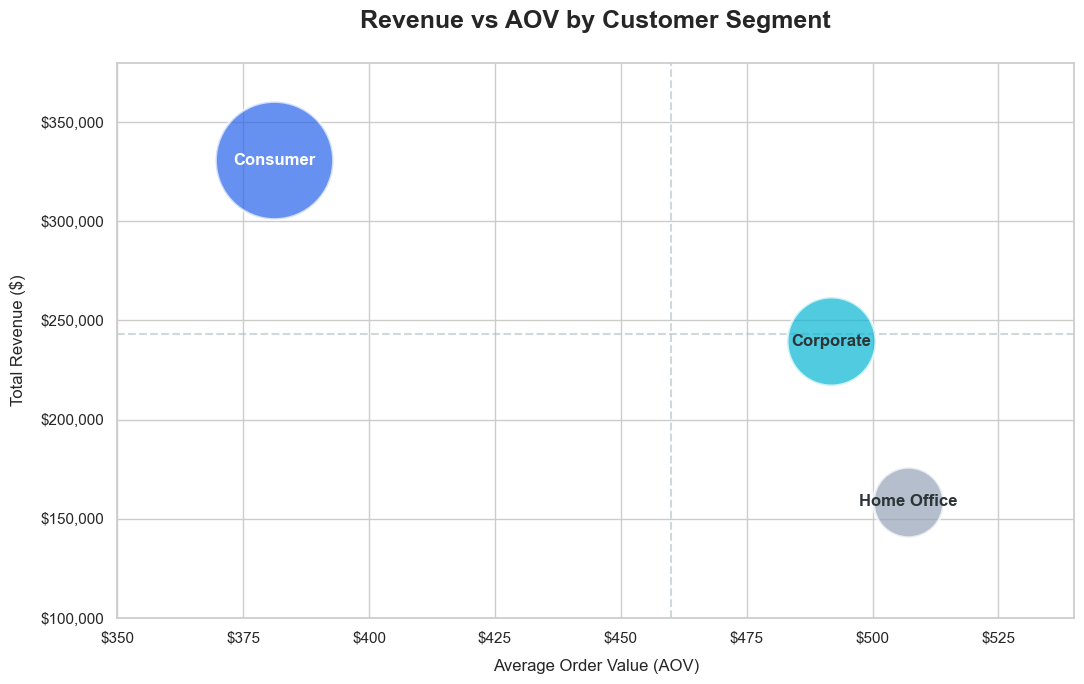

In [17]:
# 매출 vs AOV bubble chart
sns.set_theme(style="whitegrid")

palette = {
    "Consumer": "#2563EB",
    "Corporate": "#06B6D4",
    "Home Office": "#94A3B8"
}

plt.figure(figsize=(11, 7))

for i in range(len(customer_type_df)):
    seg = customer_type_df["segment"].iloc[i]
    plt.scatter(customer_type_df["aov"].iloc[i]
                , customer_type_df["revenue"].iloc[i]
                , s = customer_type_df["customer_cnt"].iloc[i] * 20 # 고객 수에 따른 버블 크기
                , color = palette[seg]
                , alpha = 0.7
                , edgecolor = "white"
                , linewidth = 2
                , zorder = 3
               )
    
    # 버블 중앙 텍스트 라벨
    plt.text(customer_type_df["aov"].iloc[i]
            , customer_type_df["revenue"].iloc[i]
            , seg
            , fontsize = 12
            , fontweight = "bold"
            , color = "white" if seg == "Consumer" else "#2D3436"
            , ha = "center"
            , va = "center"
            , zorder = 4
            )

# 평균선 추가
plt.axvline(customer_type_df["aov"].mean(), color = "#B2BEC3", linestyle = "--", alpha = 0.6, zorder = 1)
plt.axhline(customer_type_df["revenue"].mean(), color = "#B2BEC3", linestyle = "--", alpha = 0.6, zorder = 1)

plt.title("Revenue vs AOV by Customer Segment", fontsize = 18, fontweight = "bold", pad = 25) # loc= "left"
plt.xlabel("Average Order Value (AOV)", fontsize = 12, labelpad = 10)
plt.ylabel("Total Revenue ($)", fontsize = 12, labelpad = 10)

plt.gca().xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

#sns.despine(left = True, bottom = True)
plt.xlim(350, 540)
plt.ylim(100000, 380000)
plt.tight_layout()
plt.show()

In [18]:
# 매출 vs 수익률
sns.set_theme(style="whitegrid")

palette = {
    "Consumer": "#2563EB",
    "Corporate": "#06B6D4",
    "Home Office": "#94A3B8"
}

def draw_styled_bubble(df, x_col, y_col, size_col, title, x_label, y_label
                       , x_range = None, y_range = None, show_vline = True):
    plt.figure(figsize=(11, 7))

    # 버블 그리기
    for i in range(len(df)):
        seg = df["segment"].iloc[i]
        plt.scatter(df[x_col].iloc[i]
                    , df[y_col].iloc[i]
                    , s = df[size_col].iloc[i] * 25
                    , color = palette[seg]
                    , alpha = 0.75
                    , edgecolor = "white"
                    , linewidth = 2
                    , zorder = 3
                   )
        
        # 버블 중앙 텍스트 라벨
        plt.text(df[x_col].iloc[i]
                , df[y_col].iloc[i]
                , seg
                , fontsize = 11
                , fontweight = "bold"
                , color = "white" if seg == "Consumer" else "#2D3436"
                , ha = "center"
                , va = "center"
                , zorder = 4
                )

    # 평균선(추세선)
    if show_vline:
        avg_val = df[x_col].mean()
        plt.axvline(avg_val
                    , linestyle = "--"
                    , color = "#636E72"
                    , alpha = 0.8
                    , linewidth = 1.5
                    , zorder = 1
                    )
        # 평균선 라벨
        plt.text(avg_val, plt.ylim()[1], f"Avg: {avg_val:.1f}%"
                , va = "bottom", ha = "center", color = "#636E72", fontweight = "bold")

    plt.title(title, fontsize = 18, fontweight = "bold", pad = 25)
    plt.xlabel(x_label, fontsize = 12, labelpad = 10)
    plt.ylabel(y_label, fontsize = 12, labelpad = 10)

    # 축 범위
    if x_range: plt.xlim(x_range)
    if y_range: plt.ylim(y_range)

    if "Revenue" in y_label:
        plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
    if "AOV" in x_label:
        plt.gca().xaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.0f}'))
    if "Profit" in x_label:
        plt.gca().xaxis.set_major_formatter(mtick.FormatStrFormatter('%.1f%%'))

    plt.tight_layout()
    plt.show()

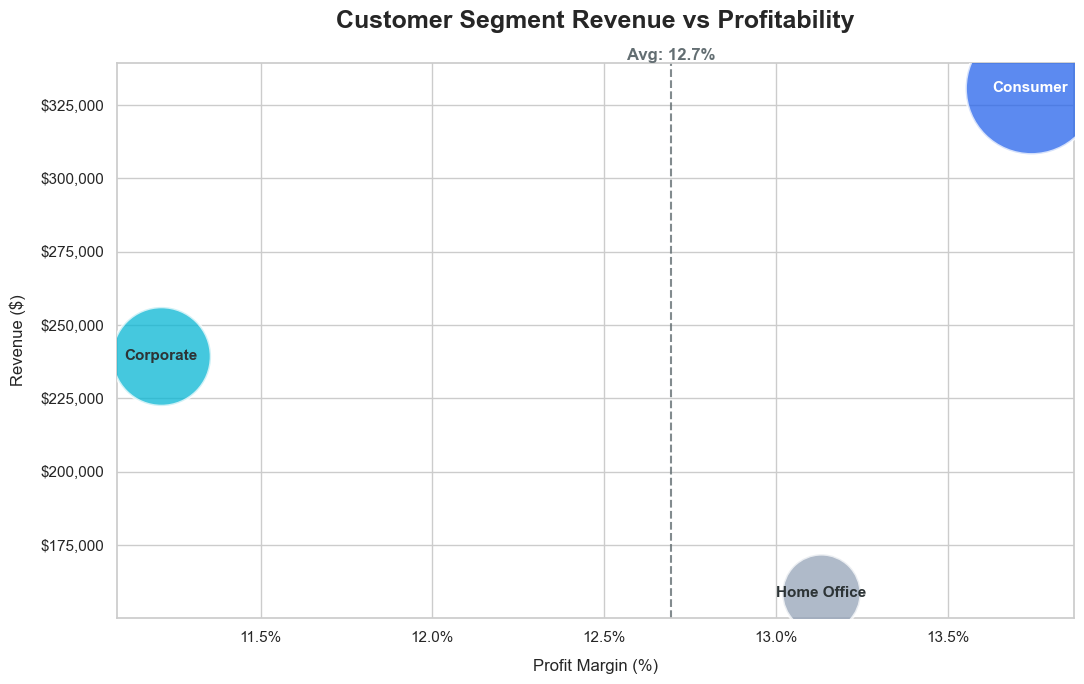

In [19]:
draw_styled_bubble(customer_type_df, "profit_margin", "revenue", "customer_cnt"
                   , title = "Customer Segment Revenue vs Profitability"
                   , x_label = "Profit Margin (%)"
                   , y_label = "Revenue ($)"
                   , show_vline = True)

In [20]:
# 세그먼트별 재구매주기
segment_reorder = pd.read_sql("""
WITH segment_order_dates AS (
    SELECT DISTINCT segment
        , customer_id
        , order_date
    FROM records
    )
    , lagged AS (
        SELECT segment
        , customer_id
        , order_Date
        , LAG(order_date) OVER (PARTITION BY segment, customer_id ORDER BY order_date) AS prev_order_date
        FROM segment_order_dates
    )
SELECT segment
    , ROUND(AVG(DATEDIFF(order_date, prev_order_date)), 2) AS avg_cycle
FROM lagged
WHERE prev_order_date IS NOT NULL
GROUP BY segment
""", conn)

In [21]:
segment_reorder

,segment,avg_cycle
0,Consumer,82.53
1,Corporate,84.74
2,Home Office,84.08


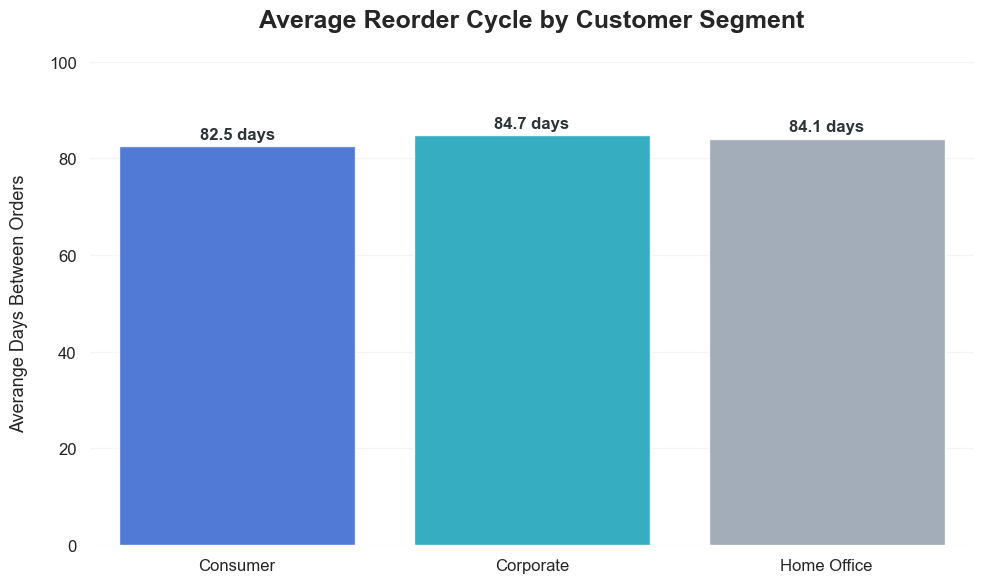

In [22]:
# 세그먼트별 재구매주기(barplot)
plt.figure(figsize = (10, 6))

colors = ["#2563EB", "#06B6D4", "#94A3B8"]

sns.barplot(x = "segment"
            , y = "avg_cycle"
            , data = segment_reorder
            , palette = colors
            , alpha = 0.9
            , edgecolor = "white"
            , linewidth = 1
           )

plt.title("Average Reorder Cycle by Customer Segment", fontsize = 18, fontweight = "bold", pad = 25)
plt.xlabel("")
plt.ylabel("Averange Days Between Orders", fontsize = 13, labelpad = 15)

for i, v in enumerate(segment_reorder["avg_cycle"]):
    plt.text(i, v + 1.5, f"{v:.1f} days", ha = "center", fontsize = 12, fontweight = "bold", color = "#2D3436")

plt.ylim(0, 100)

plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)

plt.grid(axis = "y", linestyle = "-", alpha = 0.2)
sns.despine(left = True, bottom = True)

plt.tight_layout()
plt.show()

In [23]:
# 고객별 재구매주기
customer_reorder = pd.read_sql("""
WITH customer_order_dates AS (
    SELECT DISTINCT customer_id
        , order_date
    FROM records
    )
    , lagged AS (
        SELECT customer_id
        , order_Date
        , LAG(order_date) OVER (PARTITION BY customer_id ORDER BY order_date) AS prev_order_date
        FROM customer_order_dates
    )
SELECT customer_id
    , order_date
    , prev_order_date
    , DATEDIFF(order_date, prev_order_date) AS days_between_orders
FROM lagged
WHERE prev_order_date IS NOT NULL
""", conn)

In [24]:
customer_reorder

,customer_id,order_date,prev_order_date,days_between_orders
0,AA-10375,2020-12-11,2020-09-07,95
1,AB-10060,2020-09-16,2020-05-07,132
2,AB-10060,2020-11-05,2020-09-16,50
3,AB-10060,2020-11-06,2020-11-05,1
4,AB-10105,2020-08-03,2020-05-18,77
...,...,...,...,...
964,YS-21880,2020-08-18,2020-07-03,46
965,YS-21880,2020-12-21,2020-08-18,125
966,ZC-21910,2020-06-11,2020-05-11,31
967,ZC-21910,2020-06-19,2020-06-11,8


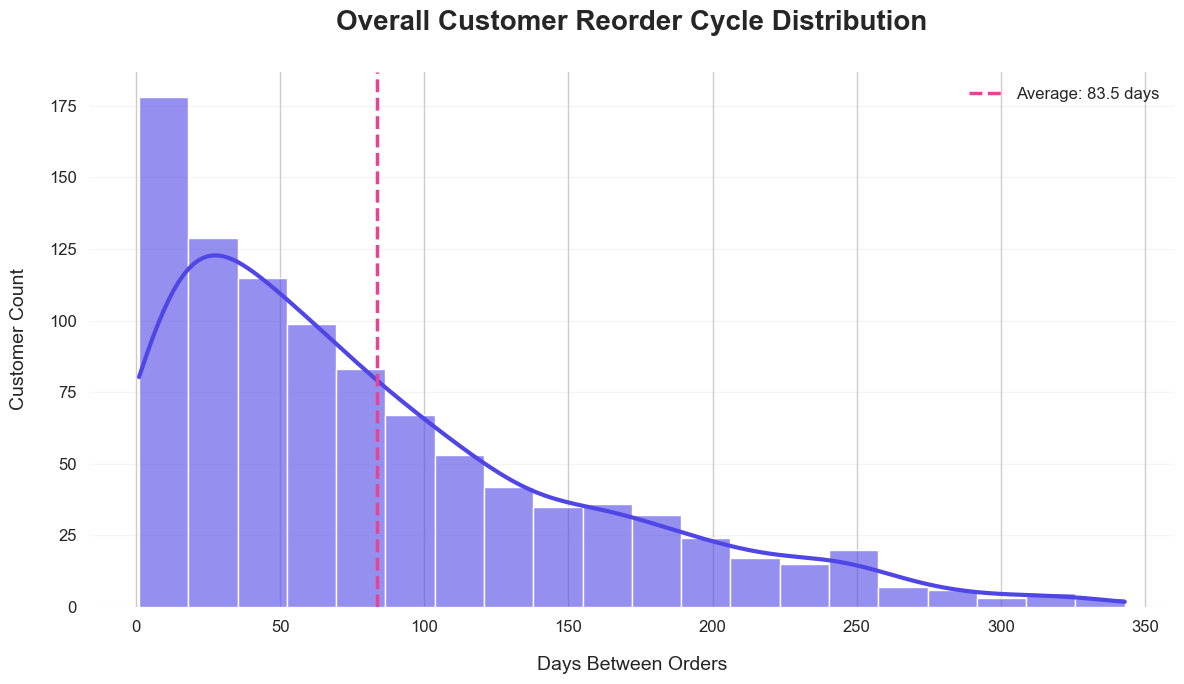

In [25]:
# 전체 고객의 재구매주기 histplot
plt.figure(figsize = (12, 7))

main_color = "#4F46E5"
line_color = "#3E2C23"

# 히스토그램 + KDE
sns.histplot(customer_reorder["days_between_orders"]
             , bins = 20
             , kde = True
             , color = main_color
             , edgecolor = "white"
             , linewidth = 1
             , alpha = 0.6
             , line_kws = {"color" : line_color, "linewidth" : 3}
            )

# 평균선
mean_cycle = customer_reorder["days_between_orders"].mean()
plt.axvline(mean_cycle, color = "#E84393", linestyle = "--", linewidth = 2.5, label = f"Average: {mean_cycle:.1f} days")

plt.title("Overall Customer Reorder Cycle Distribution", fontsize = 20, fontweight = "bold", pad = 30)
plt.xlabel("Days Between Orders", fontsize = 14, labelpad = 15)
plt.ylabel("Customer Count", fontsize = 14, labelpad = 15)

plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)

plt.grid(axis = "y", linestyle = "-", alpha = 0.2)
sns.despine(left = True, bottom = True)

plt.legend(frameon = False, fontsize = 12, loc = "upper right")
plt.tight_layout()
plt.show()

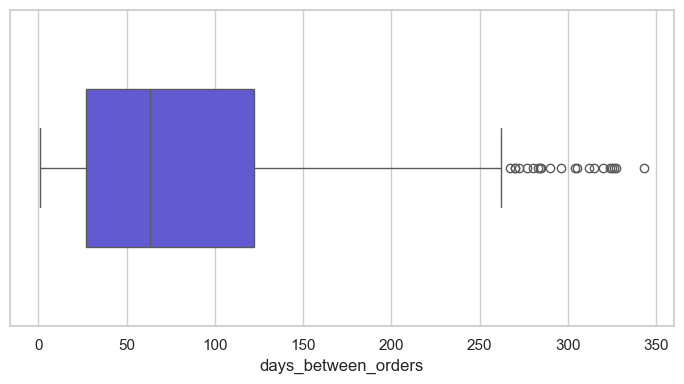

In [26]:
plt.figure(figsize = (7, 4))

sns.boxplot(x = customer_reorder["days_between_orders"]
            , color = "#4F46E5"
            , width = 0.5
           )
plt.tight_layout()
plt.show()

In [27]:
# 카테고리 별 매출 및 이익
category_df = pd.read_sql("""
SELECT category
	 , COUNT(DISTINCT order_id) AS order_cnt
	 , COUNT(DISTINCT customer_id) AS customer_cnt
     , SUM(quantity) AS total_qty
     , ROUND(SUM(sales), 2) AS revenue
     , ROUND(SUM(profit), 2) AS total_profit
     , ROUND(SUM(profit) / SUM(sales) * 100, 2) AS profit_margin
     , ROUND(SUM(sales) / COUNT(DISTINCT order_id), 2) AS sales_per_order
     , ROUND(SUM(sales) / COUNT(DISTINCT customer_id), 2) AS sales_per_customer
     , COUNT(DISTINCT product_id) AS product_cnt
FROM records
GROUP BY category
ORDER BY revenue DESC
""", conn)

In [28]:
category_df

,category,order_cnt,customer_cnt,total_qty,revenue,total_profit,profit_margin,sales_per_order,sales_per_customer,product_cnt
0,Technology,521,386,2334.0,269517.89,50510.13,18.74,517.31,698.23,298
1,Office Supplies,1256,634,7571.0,244769.04,39410.40,16.10,194.88,386.07,903
2,Furniture,561,401,2426.0,214747.23,3217.60,1.50,382.79,535.53,314


In [29]:
# 월별 카테고리 매출, pu, arppu
category_month = pd.read_sql("""
SELECT DATE_FORMAT(order_date, "%Y-%m") AS month
    , category
    , COUNT(DISTINCT customer_id) AS pu
    , ROUND(SUM(sales), 2) AS revenue
    , ROUND(SUM(sales) / COUNT(DISTINCT customer_id), 2) AS arppu
    , ROUND(SUM(profit) / SUM(sales) * 100, 2) AS profit_margin
FROM records
GROUP BY month, category
ORDER BY month, category""", conn)

In [30]:
category_month

,month,category,pu,revenue,arppu,profit_margin
0,2020-01,Furniture,21,5964.03,284.00,-0.66
1,2020-01,Office Supplies,52,21274.29,409.12,15.33
2,2020-01,Technology,25,16733.05,669.32,23.42
3,2020-02,Furniture,21,6866.34,326.97,-2.90
4,2020-02,Office Supplies,39,7356.98,188.64,12.78
5,2020-02,Technology,19,5955.06,313.42,14.00
6,2020-03,Furniture,31,10893.44,351.40,9.19
7,2020-03,Office Supplies,85,14550.29,171.18,18.67
8,2020-03,Technology,44,33428.62,759.74,33.01
9,2020-04,Furniture,36,9065.96,251.83,2.23


In [31]:
pu_pivot = category_month.pivot(index = 'month', columns = 'category', values = 'pu').reindex(category_month["month"].unique())
pu_pivot

category,Furniture,Office Supplies,Technology
month,,,
2020-01,21,52,25
2020-02,21,39,19
2020-03,31,85,44
2020-04,36,85,25
2020-05,44,89,38
2020-06,38,89,37
2020-07,43,71,43
2020-08,29,82,32
2020-09,64,162,72


In [32]:
arppu_pivot = category_month.pivot(index = 'month', columns = 'category', values = 'arppu').reindex(category_month["month"].unique())
revenue_pivot = category_month.pivot(index = 'month', columns = 'category', values = 'revenue').reindex(category_month["month"].unique())

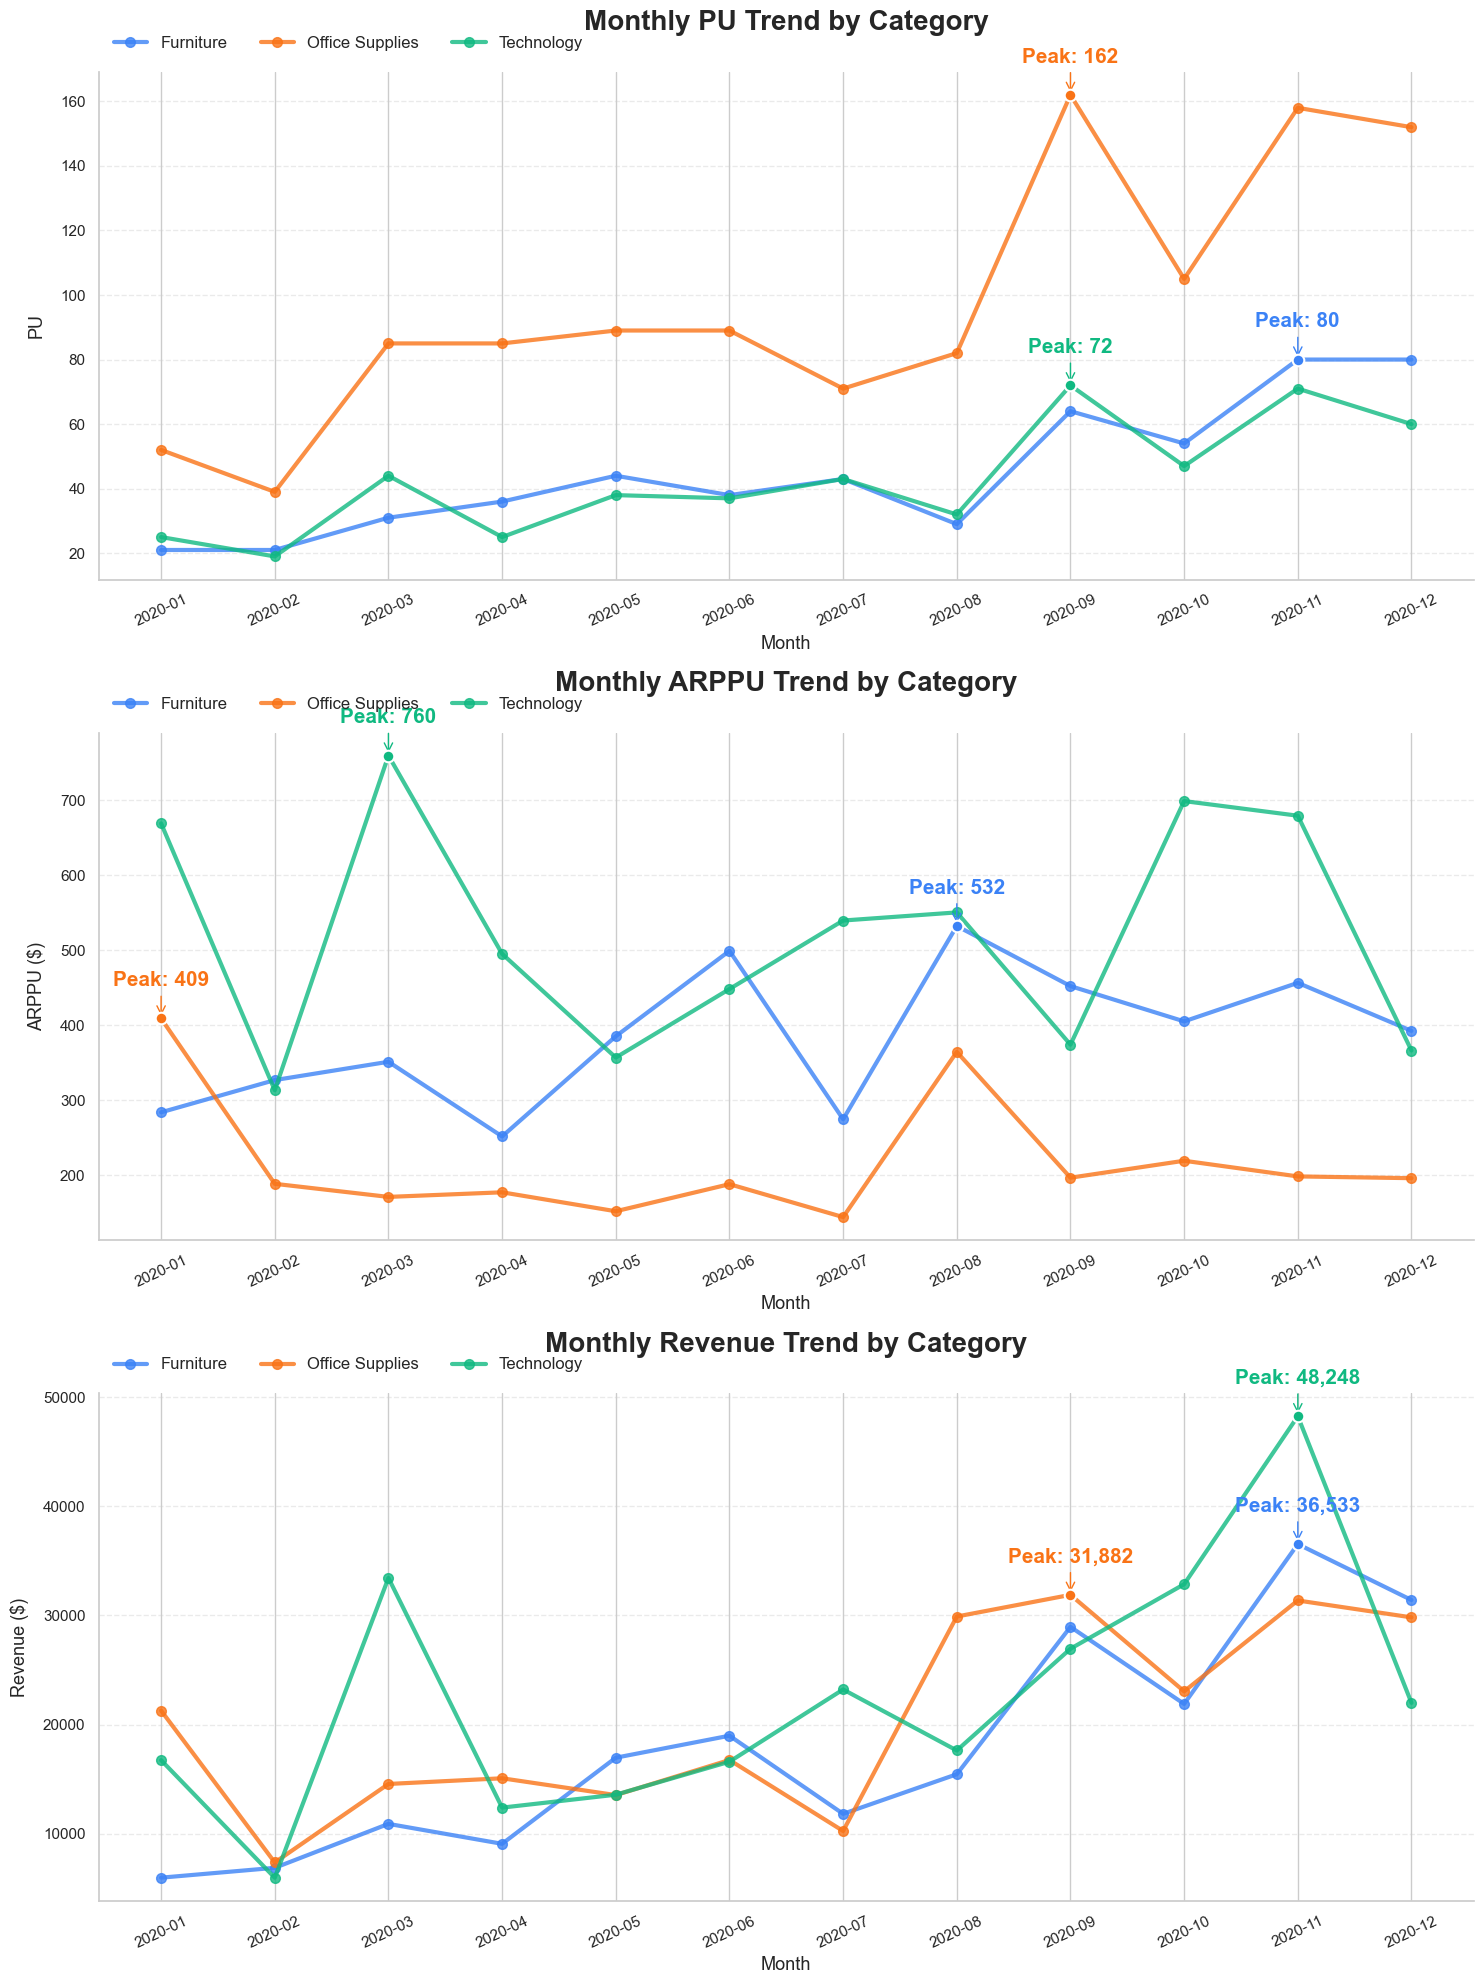

In [33]:
# line plot (PU)
fig, axes = plt.subplots(3, 1, figsize = (15, 20))

colors = {
    'Office Supplies': '#F97316', 
    'Technology': '#10B981',      
    'Furniture': '#3B82F6'  
}

pivots = [pu_pivot, arppu_pivot, revenue_pivot]

titles = [
    "Monthly PU Trend by Category",
    "Monthly ARPPU Trend by Category",
    "Monthly Revenue Trend by Category"
]

ylabels = [
    "PU",
    "ARPPU ($)",
    "Revenue ($)"
]

for ax, df, title, ylabel in zip(axes, pivots, titles, ylabels):

    offset = (df.max().max() - df.min().min()) * 0.07

    for col in df.columns:
        ax.plot(df.index, df[col], marker = 'o', markersize = 7, color = colors[col], linewidth = 3, label = col, alpha = 0.8)

        max_idx = df[col].idxmax()
        max_val = df[col].max()

        ax.scatter(max_idx, max_val, s = 70, color = colors[col], edgecolor = "white", linewidth = 1.5, zorder = 5)

        ax.annotate(f'Peak: {max_val:,.0f}', xy = (max_idx, max_val), xytext = (max_idx, max_val + offset)
                     , ha = 'center', fontsize = 15, fontweight = 'bold', color = colors[col]
                     , arrowprops = dict(arrowstyle = "->", color = colors[col]))

    ax.set_title(title, fontsize = 20, fontweight = "bold", pad = 30)
    ax.set_xlabel("Month", fontsize = 13)
    ax.set_ylabel(ylabel, fontsize = 13, labelpad = 10)

    ax.tick_params(axis = "x", rotation = 25, labelsize = 11)
    ax.tick_params(axis = "y", labelsize = 11)

    ax.grid(axis = "y", linestyle = "--", alpha = 0.4)

    ax.legend(frameon = False, fontsize = 12, loc = "upper left", bbox_to_anchor = (0, 1.1), ncol = 3)

    sns.despine(ax = ax)

plt.tight_layout()
plt.show()

In [35]:
category_reorder = pd.read_sql("""WITH category_order_dates AS (
    SELECT DISTINCT
           category,
           customer_id,
           order_date
    FROM records
),
lagged AS (
    SELECT
        category,
        customer_id,
        order_date,
        LAG(order_date) OVER (
            PARTITION BY category, customer_id
            ORDER BY order_date
        ) AS prev_order_date
    FROM category_order_dates
)
SELECT
    category,
    ROUND(AVG(DATEDIFF(order_date, prev_order_date)), 2) AS avg_reorder_days
FROM lagged
WHERE prev_order_date IS NOT NULL
GROUP BY category
ORDER BY avg_reorder_days""", conn)

In [36]:
category_reorder

,category,avg_reorder_days
0,Office Supplies,93.45
1,Furniture,112.01
2,Technology,115.07


In [37]:
category_summary = (
    category_month
    .groupby("category")
    .agg({
        "pu":"mean",
        "arppu":"mean",
        "revenue":"sum",
        "profit_margin":"mean"
    })
    .reset_index()
)
# Revenue Share(%)
category_summary["revenue_share"] = (
    category_summary["revenue"]
    / category_summary["revenue"].sum()
    * 100
)

category_summary = category_summary.merge(category_reorder, on = "category", how = "left").rename(columns = {"avg_reorder_days" : "avg_purchase_cycle"})

# Revenue 순으로 정렬(선택)
category_summary = category_summary.sort_values(
    "revenue_share",
    ascending=False
)

category_summary

,category,pu,arppu,revenue,profit_margin,revenue_share,avg_purchase_cycle
2,Technology,42.750000,521.070000,269517.88,17.223333,36.969171,115.07
1,Office Supplies,97.416667,217.179167,244769.04,17.217500,33.574427,93.45
0,Furniture,45.083333,384.409167,214747.23,1.348333,29.456402,112.01


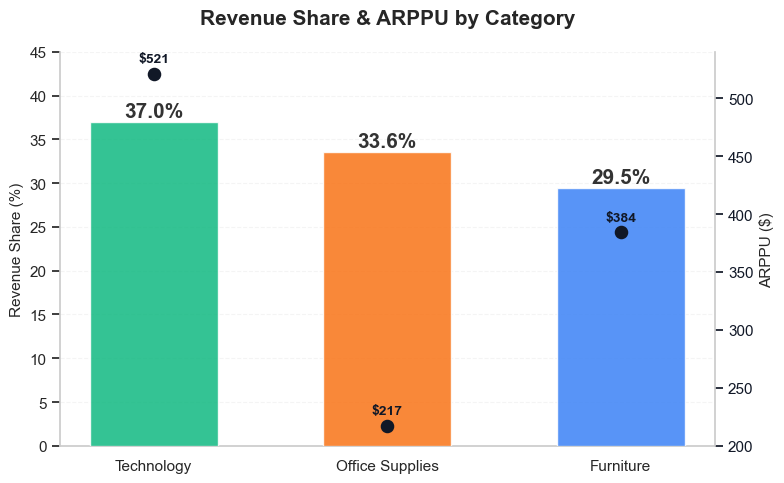

In [39]:
fig, ax1 = plt.subplots(figsize=(8,5))

x = np.arange(len(category_summary))

# Revenue Share (Bar)
colors = {
    'Office Supplies': '#F97316', 
    'Technology': '#10B981',      
    'Furniture': '#3B82F6'  
}

bar_colors = [colors[c] for c in category_summary["category"]]

bars = ax1.bar(x, category_summary["revenue_share"], color = bar_colors, width = 0.55, alpha = 0.85, zorder = 3)

ax1.set_ylabel("Revenue Share (%)", fontsize=11)
ax1.set_ylim(0, 45)

# Revenue Shapr Label
for bar in bars:
    height = bar.get_height()

    ax1.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.6,
        f"{height:.1f}%",
        ha = "center",
        fontsize = 15,
        fontweight = "bold",
        color = "#333333"
    )

# ARPPU (Dot Plot)
ax2 = ax1.twinx()

ax2.scatter(x, category_summary["arppu"], s = 60, color = "#111827", linewidth = 2, zorder = 5)


ax2.set_ylabel("ARPPU ($)", fontsize=11)
ax2.set_ylim(200, 540)

# arppu Label
for i, value in enumerate(category_summary["arppu"]):

    ax2.text(i, value + 10, f"${value:.0f}", ha = "center"
             , fontsize = 10, color = "#111827", fontweight = "bold")

ax2.tick_params(axis='y', colors='#111827')

# -----------------------------
# X axis
# -----------------------------

ax1.set_xticks(x)
ax1.set_xticklabels(category_summary["category"])

ax1.set_axisbelow(True)

ax1.grid(axis = "y", linestyle = "--", linewidth = 0.8, alpha=0.2)
ax1.grid(axis = "x", visible = False)
ax2.grid(False)

# 테두리 제거
for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)

ax1.spines['right'].set_visible(False)

ax2.spines['left'].set_visible(False)
ax2.spines["bottom"].set_visible(False)

plt.title("Revenue Share & ARPPU by Category", fontsize=15, weight="bold", pad = 20)

plt.tight_layout()
plt.show()

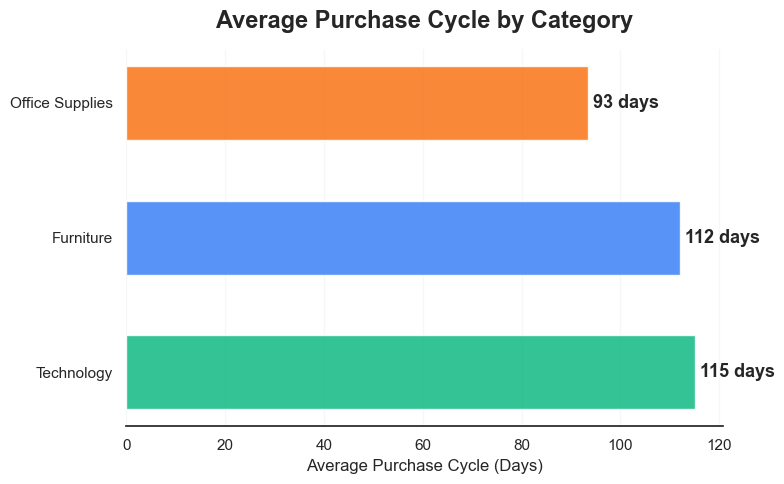

In [40]:
sns.set_theme(style="white")

cycle_df = category_summary.sort_values("avg_purchase_cycle", ascending=False)

colors = {
    'Office Supplies': '#F97316', 
    'Technology': '#10B981',      
    'Furniture': '#3B82F6'  
}

fig, ax = plt.subplots(figsize=(8,5))

bars = ax.barh(cycle_df["category"], cycle_df["avg_purchase_cycle"], color=[colors[c] for c in cycle_df["category"]], height=0.55, alpha = 0.85)

# 값 표시
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 1,
        bar.get_y() + bar.get_height()/2,
        f"{width:.0f} days",
        va="center",
        fontsize=13,
        fontweight="bold"
    )

ax.set_xlabel("Average Purchase Cycle (Days)", fontsize=12)
ax.set_ylabel("")
ax.set_title("Average Purchase Cycle by Category", fontsize=17, fontweight="bold", pad=15)

ax.grid(axis="x", alpha=0.15)

sns.despine(left=True)

plt.tight_layout()
plt.show()

In [50]:
# 코호트(리텐션) heatmap data
cohort_df = pd.read_sql("""
WITH first_order AS (
    SELECT customer_id
         , DATE_FORMAT(MIN(order_date), "%Y-%m") AS cohort_month
    FROM records
    GROUP BY customer_id
), activity AS (
    SELECT DISTINCT customer_id
         , DATE_FORMAT(order_date, "%Y-%m") AS order_month
    FROM records
), cohort_base AS (
    SELECT f.customer_id
        , f.cohort_month
        , a.order_month
        , PERIOD_DIFF(DATE_FORMAT(STR_TO_DATE(CONCAT(a.order_month, '-01'), "%Y-%m-%d"), '%Y%m'),
        			  DATE_FORMAT(STR_TO_DATE(CONCAT(f.cohort_month, "-01"), "%Y-%m-%d"), '%Y%m')
                      ) AS month_index
    FROM first_order f
    	INNER JOIN activity a ON a.customer_id = f.customer_id
), cohort_counts AS (
    SELECT cohort_month
        , month_index
        , COUNT(DISTINCT customer_id) AS active_customers
    FROM cohort_base
    GROUP BY cohort_month, month_index
), cohort_size AS (
    SELECT cohort_month
        , COUNT(DISTINCT customer_id) AS cohort_size
    FROM first_order
    GROUP BY cohort_month
)
SELECT c.cohort_month
    , c.month_index
    , c.active_customers
    , s.cohort_size
    , ROUND(c.active_customers * 100 / s.cohort_size, 2) AS retention_rate
FROM cohort_counts c
	INNER JOIN cohort_size s ON s.cohort_month = c.cohort_month
ORDER BY c.cohort_month, c.month_index
""", conn)

In [51]:
cohort_pivot = cohort_df.pivot(index = "cohort_month"
                               , columns = "month_index"
                               , values = "retention_rate")
cohort_pivot

month_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2020-01,100.0,2.99,11.94,19.40,13.43,5.97,13.43,13.43,23.88,13.43,23.88,26.87
2020-02,100.0,10.42,12.50,12.50,14.58,8.33,12.50,33.33,20.83,29.17,27.08,NaN
2020-03,100.0,12.75,14.71,11.76,14.71,12.75,27.45,19.61,25.49,23.53,NaN,NaN
2020-04,100.0,15.58,18.18,16.88,14.29,25.97,16.88,28.57,33.77,NaN,NaN,NaN
2020-05,100.0,11.43,14.29,17.14,24.29,15.71,35.71,22.86,NaN,NaN,NaN,NaN
2020-06,100.0,8.82,17.65,25.00,17.65,23.53,20.59,NaN,NaN,NaN,NaN,NaN
2020-07,100.0,15.56,20.00,20.00,17.78,24.44,NaN,NaN,NaN,NaN,NaN,NaN
2020-08,100.0,28.13,15.63,53.13,28.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-09,100.0,12.50,23.44,14.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


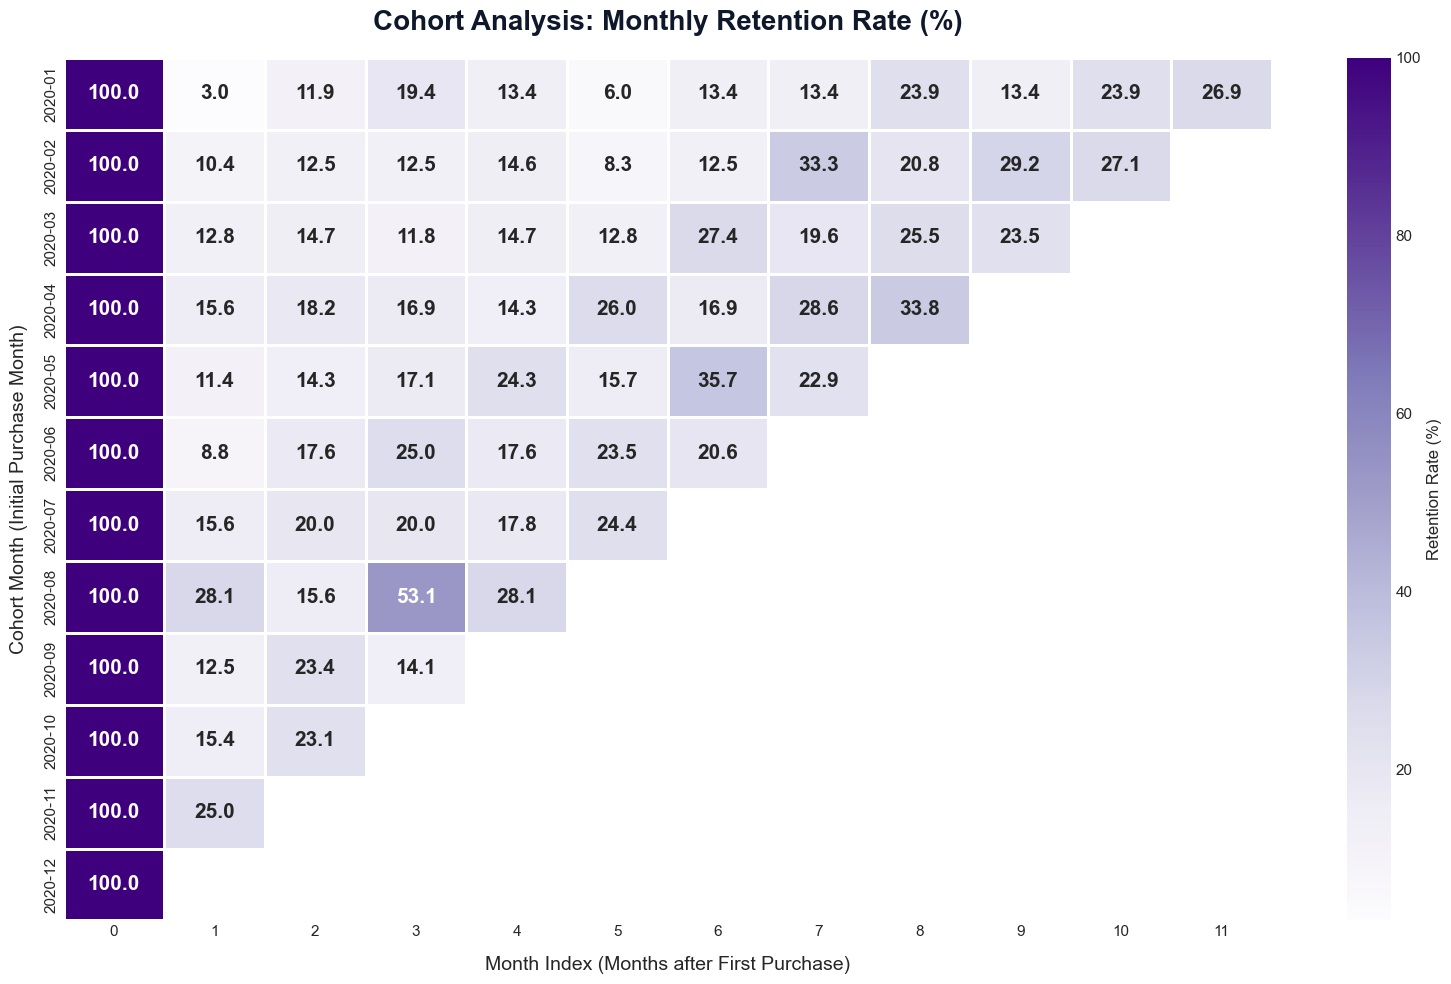

In [52]:
plt.figure(figsize = (16, 10))
sns.set_style("white")

sns.heatmap(cohort_pivot
            , annot = True
            , fmt = ".1f"
            , cmap = "Purples"
            , linewidths = 1.0 # 칸 사이 구분선
            , linecolor = "white"
            , cbar_kws = {"label" : "Retention Rate (%)"}
            , annot_kws = {"size" : 15, "weight" : "bold"}
           )

plt.title("Cohort Analysis: Monthly Retention Rate (%)", fontsize = 20, fontweight = "bold", pad = 20, color = "#0F172A")
plt.xlabel("Month Index (Months after First Purchase)", fontsize = 14, labelpad = 12)
plt.ylabel("Cohort Month (Initial Purchase Month)", fontsize = 14, labelpad = 12)

plt.tight_layout()
plt.show()

In [77]:
# 할인
df = pd.read_sql("""SELECT
    CASE
        WHEN discount = 0 THEN '0%'
        WHEN discount > 0 AND discount <= 0.1 THEN '0~10%'
        WHEN discount > 0.1 AND discount <= 0.2 THEN '10~20%'
        WHEN discount > 0.2 THEN '20%+'
    END AS discount_group,
    COUNT(DISTINCT order_id) AS order_cnt,
    ROUND(SUM(sales), 2) AS revenue,
    ROUND(SUM(profit), 2) AS total_profit,
    ROUND(AVG(sales), 2) AS avg_sales_per_row,
    ROUND(AVG(profit), 2) AS avg_profit_per_row,
    ROUND(SUM(profit) * 100 / SUM(sales), 2) AS profit_margin
FROM records
GROUP BY discount_group
ORDER BY
    CASE discount_group
        WHEN '0%' THEN 1
        WHEN '0~10%' THEN 2
        WHEN '10~20%' THEN 3
        WHEN '20%+' THEN 4
    END""", conn)

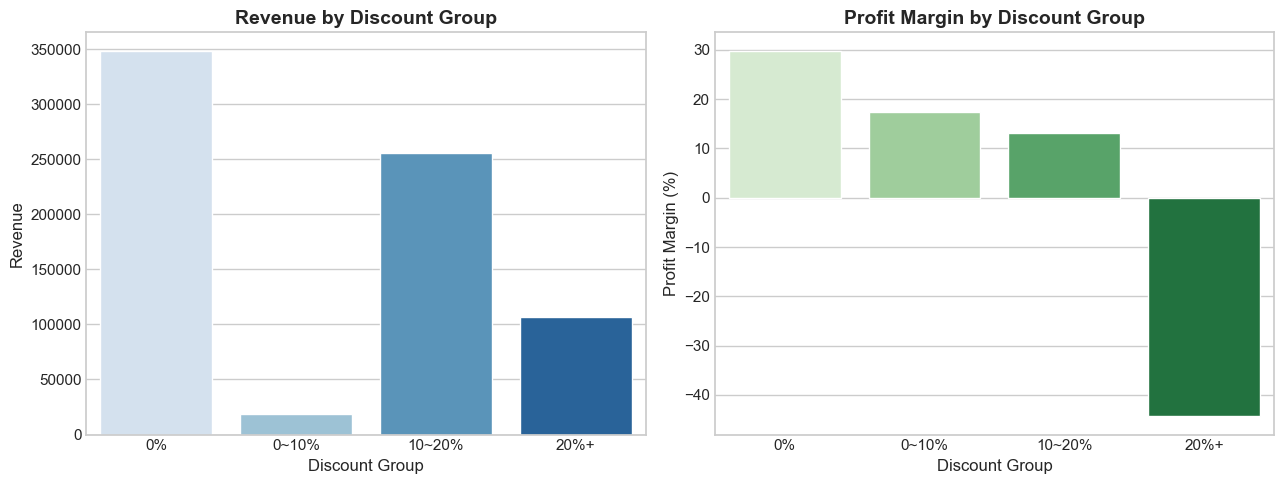

In [78]:
# 할인 구간별 Revenue vs Profit
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=df,
    x="discount_group",
    y="revenue",
    palette="Blues",
    ax=axes[0]
)
axes[0].set_title("Revenue by Discount Group", fontsize=14, weight="bold")
axes[0].set_xlabel("Discount Group")
axes[0].set_ylabel("Revenue")

sns.barplot(
    data=df,
    x="discount_group",
    y="profit_margin",
    palette="Greens",
    ax=axes[1]
)
axes[1].set_title("Profit Margin by Discount Group", fontsize=14, weight="bold")
axes[1].set_xlabel("Discount Group")
axes[1].set_ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

In [79]:
# 지역별 분석
region_df = pd.read_sql("""SELECT
    region,
    COUNT(DISTINCT order_id) AS order_cnt,
    COUNT(DISTINCT customer_id) AS customer_cnt,
    ROUND(SUM(sales),2) AS revenue,
    ROUND(SUM(profit),2) AS profit,
    ROUND(SUM(profit)*100/SUM(sales),2) AS profit_margin,
    ROUND(SUM(sales)/COUNT(DISTINCT customer_id),2) AS ARPPU
FROM records
GROUP BY region
ORDER BY revenue DESC""", conn)

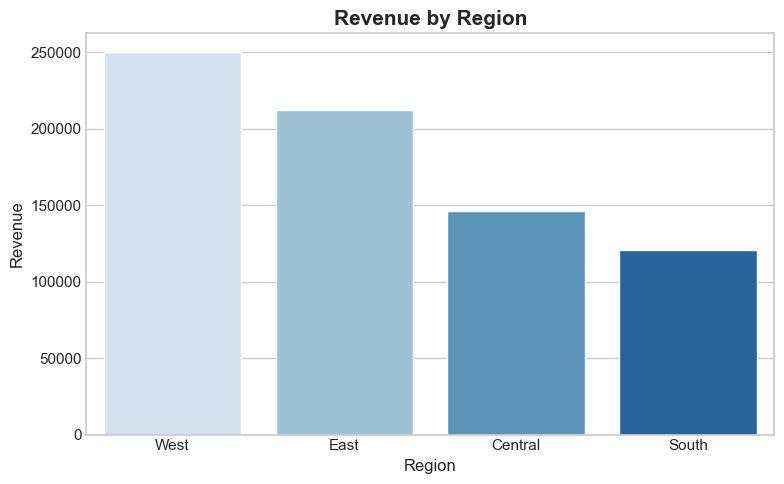

In [80]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=region_df,
    x="region",
    y="revenue",
    palette="Blues"
)

plt.title("Revenue by Region", fontsize=15, weight="bold")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()